# 02 · Feature engineering, chronological split & baselines

**Goal.** Turn the cleaned weekly data into a supervised learning table where each row is one forecast:
*standing at the end of week t, predict cases in week t+1 for one district*. Then:
1. split it **chronologically** (no shuffling, no peeking at the future),
2. define the preprocessing pipeline (imputation + one-hot) that every model reuses,
3. score the **naive** and **seasonal** baselines that every ensemble must beat,
4. decide whether to model **raw cases or log1p(cases)**,
5. compute the district-specific **risk thresholds**.

All logic is in `src/features.py` and `src/evaluate.py`.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))            # make `src` importable from the notebook
warnings.filterwarnings("ignore")

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src import config, viz
viz.set_style()
pd.set_option("display.width", 140, "display.max_columns", 30)

from src import data, features as F, evaluate as E
dengue = data.load_dengue_clean()
weather = data.load_weather_weekly()
print("weather available:", weather is not None)

weather available: True


## 1. Build the feature table

| Feature group | Columns | Uses data from |
|---|---|---|
| Lagged cases | `cases_lag1..4` | weeks t, t-1, t-2, t-3 |
| Rolling stats | `rolling_mean_4`, `rolling_std_4`, `rolling_mean_8` | windows ending at week t |
| Lagged weather | `rain_mm_lag1..8`, `temp_c_lag1..8`, `humidity_pct_lag1..8` | weeks t … t-7 |
| Calendar | `week_sin`, `week_cos`, `year` | the target week's calendar (known in advance) |
| Location | `district` (one-hot inside the pipeline) | — |

Weather lags go up to 8 weeks because notebook 01 showed rainfall/humidity correlate most with cases 7–9 weeks later.
Cyclical encoding (`sin`/`cos`) tells the model that week 52 is next to week 1.

In [2]:
panel = F.build_panel(dengue, weather)
num_feats = F.numeric_features(with_weather=weather is not None)
print("panel shape:", panel.shape, "| numeric features:", len(num_feats), "| + district one-hot")
panel[panel.district == "Colombo"][["origin_date", "target_date", "target", "cases_lag1", "cases_lag2",
                                    "rolling_mean_4", "rain_mm_lag1", "rain_mm_lag8", "week", "week_sin"]].iloc[700:705]

panel shape: (26753, 42) | numeric features: 34 | + district one-hot


,origin_date,target_date,target,cases_lag1,cases_lag2,rolling_mean_4,rain_mm_lag1,rain_mm_lag8,week,week_sin
4816,2020-05-23,2020-05-30,81.0,80.0,67.0,44.25,77.2,67.9,22,0.472823
4817,2020-05-30,2020-06-06,62.0,81.0,80.0,63.00,21.5,36.4,23,0.363552
4818,2020-06-06,2020-06-13,70.0,62.0,81.0,72.50,124.7,28.6,24,0.249016
4819,2020-06-13,2020-06-20,58.0,70.0,62.0,73.25,43.7,21.9,25,0.130874
4820,2020-06-20,2020-06-27,50.0,58.0,70.0,67.75,55.5,29.4,26,0.010837


### Leakage checks
If the features were aligned correctly, the target of week t must re-appear as `cases_lag1` in the next row,
and every feature window must end on or before the origin week.

In [3]:
ok = True
for d, g in panel.groupby("district"):
    ok &= np.allclose(g.target.values[:-1], g.cases_lag1.values[1:], equal_nan=True)
print("target(t) == cases_lag1(t+1) for every district:", ok)
print("target_date always after origin_date:", bool((panel.target_date > panel.origin_date).all()))

target(t) == cases_lag1(t+1) for every district: True
target_date always after origin_date: True


## 2. Chronological split
* **train**: target weeks in 2007–2021 (after an 8-week warm-up per region)
* **validation**: 2022, used for early stopping, the log-vs-raw decision and hybrid weights
* **test**: 2023 onward, **excluding the 2 most recent weeks**, which may still receive late reports.
* **forecast**: the latest week of every district (target unknown), used by the dashboard.

Rows are dropped **only when the target is missing** (a missing report in week t+1). Missing lag values are kept
and handled inside the pipeline.

In [4]:
splits = F.split_panel(panel)
pd.DataFrame({k: {"rows": len(v), "first target week": v.target_date.min().date(), "last target week": v.target_date.max().date(),
                  "mean target": round(v.target.mean(), 1) if v.target.notna().any() else None}
              for k, v in splits.items()}).T

,rows,first target week,last target week,mean target
train,19800,2007-02-24,2021-12-25,30.1
val,1329,2022-01-01,2022-12-24,23.8
test,4965,2022-12-31,2026-08-24,54.1
excluded_recent,52,2026-08-31,2026-09-07,25.3
forecast,26,2026-09-14,2026-09-14,None


In [5]:
dropped_target = panel[(panel.history_weeks > F.WARMUP_WEEKS) & panel.target.isna() & (panel.origin_date < panel.origin_date.max())]
print("rows dropped because the target week was a missing report:", len(dropped_target))
print("rows dropped as warm-up (first 8 weeks of each region):", int((panel.history_weeks <= F.WARMUP_WEEKS).sum()))
print("\nNaN counts in TRAIN features (handled by the imputer, not dropped):")
print(splits["train"][num_feats].isna().sum().loc[lambda s: s > 0].to_string())

rows dropped because the target week was a missing report: 373
rows dropped as warm-up (first 8 weeks of each region): 208

NaN counts in TRAIN features (handled by the imputer, not dropped):
cases_lag1         3
cases_lag2         6
cases_lag3         9
cases_lag4        12
rolling_mean_4     6
rolling_std_4      6
rolling_mean_8    12


## 3. Preprocessing pipeline (fit on training data only)
`SimpleImputer(strategy="median", add_indicator=True)` replaces a missing lag with the **training** median and adds a
0/1 *was-missing* column, so the model can learn that an imputed value is less trustworthy. `OneHotEncoder` encodes the
district. Because this lives inside each model's `Pipeline`, it is re-fit on the training part of every
`TimeSeriesSplit` fold during tuning, so validation/test statistics never leak into training.

In [6]:
import joblib
prep = F.make_preprocessor(num_feats)
X_train = prep.fit_transform(splits["train"][F.all_features(weather is not None)])
names = prep.get_feature_names_out()
print("transformed training matrix:", X_train.shape)
print("was-missing indicator columns:", [n for n in names if n.startswith("missingindicator")])
config.MODELS_DIR.mkdir(exist_ok=True)
joblib.dump(prep, config.MODELS_DIR / "preprocessor.joblib", compress=3)
print("saved models/preprocessor.joblib")

transformed training matrix: (19800, 67)
was-missing indicator columns: ['missingindicator_cases_lag1', 'missingindicator_cases_lag2', 'missingindicator_cases_lag3', 'missingindicator_cases_lag4', 'missingindicator_rolling_mean_4', 'missingindicator_rolling_std_4', 'missingindicator_rolling_mean_8']
saved models/preprocessor.joblib


## 4. Baselines
* **Naive**: next week = this week (`cases_lag1`, or the last observed week if this week is missing).
* **Seasonal naive**: next week = the same week last year.

Every model's `MAE_vs_naive_pct` in `models/results.csv` is measured against the naive baseline, the fairest
yard-stick given week-to-week autocorrelation of 0.855.

In [7]:
for f in [E.RESULTS_CSV, E.PREDICTIONS_CSV]:            # start a fresh results table for this run
    f.unlink(missing_ok=True)

rows = []
for split_name in ["val", "test"]:
    s = splits[split_name]
    for name, col in [(E.NAIVE_NAME, "naive_pred"), ("Seasonal naive (last year)", "seasonal_pred")]:
        rows.append({"split": split_name, "model": name, **E.regression_metrics(s.target, s[col])})
base = pd.DataFrame(rows).round(3)
display(base)

test = splits["test"]
E.record_result(E.NAIVE_NAME, "Baseline", test.target, test.naive_pred)
E.record_result("Seasonal naive (last year)", "Baseline", test.target, test.seasonal_pred)
E.save_predictions(E.NAIVE_NAME, test, test.naive_pred)
E.save_predictions("Seasonal naive (last year)", test, test.seasonal_pred)
E.load_results()

,split,model,MAE,RMSE,R2,sMAPE
0,val,Naive (last week),11.566,20.505,0.283,61.413
1,val,Seasonal naive (last year),20.099,35.125,-1.104,106.782
2,test,Naive (last week),16.966,51.326,0.770,47.430
3,test,Seasonal naive (last year),39.103,99.582,0.136,80.719


,model,family,MAE,RMSE,R2,sMAPE,train_time_s,MAE_vs_naive_pct,RMSE_vs_naive_pct
0,Naive (last week),Baseline,16.9656,51.3258,0.7704,47.4302,0.0,0.0000,0.0000
1,Seasonal naive (last year),Baseline,39.1025,99.5825,0.1358,80.7185,0.0,-130.4812,-94.0203


## 5. Target transform: raw cases or log1p(cases)?
Weekly cases are heavily right-skewed (median 9, max 2,631). A tree trained with squared error on raw counts
spends many splits on a few outbreak weeks; `log1p` compresses the spikes, and `expm1` converts predictions back.
We test both with two different ensembles (Random Forest = bagging, LightGBM = boosting), trained on 2007–2021 and
scored on 2022, and keep whichever gives the **lower mean validation MAE**. The test set is not touched.

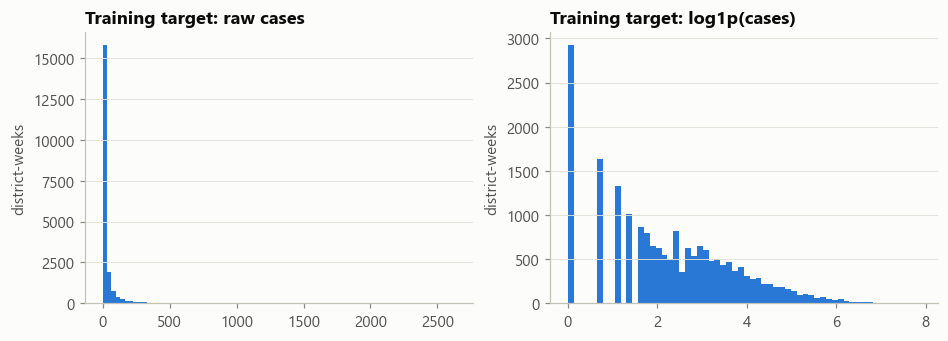

skewness raw = 10.81  |  skewness log1p = 0.33


In [8]:
y = splits["train"].target
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
axes[0].hist(y, bins=80, color=viz.SERIES[0]); axes[0].set_title("Training target: raw cases")
axes[1].hist(np.log1p(y), bins=60, color=viz.SERIES[0]); axes[1].set_title("Training target: log1p(cases)")
for ax in axes: ax.set_ylabel("district-weeks")
viz.save(fig, "fe_target_distribution"); plt.show()
print(f"skewness raw = {y.skew():.2f}  |  skewness log1p = {np.log1p(y).skew():.2f}")

In [9]:
import time
from sklearn.ensemble import RandomForestRegressor
from lightgbm import LGBMRegressor

feats = F.all_features(weather is not None)
tr, va = splits["train"], splits["val"]
candidates = {
    "RandomForest": lambda: RandomForestRegressor(n_estimators=300, max_features=0.5, min_samples_leaf=3,
                                                  n_jobs=-1, random_state=config.RANDOM_STATE),
    "LightGBM": lambda: LGBMRegressor(n_estimators=400, learning_rate=0.05, num_leaves=31,
                                      random_state=config.RANDOM_STATE, verbose=-1),
}
rows = []
for name, make in candidates.items():
    for use_log in [False, True]:
        pipe = F.make_model_pipeline(make(), num_feats, use_log=use_log)
        t0 = time.time(); pipe.fit(tr[feats], tr.target)
        m = E.regression_metrics(va.target, pipe.predict(va[feats]))
        rows.append({"model": name, "target": "log1p" if use_log else "raw", **m, "fit_s": round(time.time() - t0, 1)})
tt = pd.DataFrame(rows)
naive_val_mae = E.regression_metrics(va.target, va.naive_pred)["MAE"]
tt["MAE_vs_naive_pct"] = E.improvement(tt.MAE, naive_val_mae)
display(tt.round(3))

mean_mae = tt.groupby("target").MAE.mean()
USE_LOG = bool(mean_mae["log1p"] < mean_mae["raw"])
print("mean validation MAE by target:", mean_mae.round(3).to_dict())
print("DECISION -> train all models on", "log1p(cases)" if USE_LOG else "raw cases")

,model,target,MAE,RMSE,R2,sMAPE,fit_s,MAE_vs_naive_pct
0,RandomForest,raw,10.625,17.976,0.449,56.126,17.6,8.131
1,RandomForest,log1p,10.391,17.515,0.477,58.403,20.3,10.157
2,LightGBM,raw,10.593,18.058,0.444,57.241,0.8,8.412
3,LightGBM,log1p,10.534,17.722,0.464,59.985,0.9,8.920


mean validation MAE by target: {'log1p': 10.463, 'raw': 10.609}
DECISION -> train all models on log1p(cases)


## 6. Risk thresholds (training period only)
For each district: **Low** ≤ 50th percentile of its 2007–2021 weekly cases < **Medium** ≤ 75th percentile < **High**.
Using each district's own history means "High" in Mannar is a busy week *for Mannar*, not compared with Colombo.

In [10]:
thr = F.compute_risk_thresholds(dengue)
thr_df = pd.DataFrame(thr).T.round(1).sort_values("high", ascending=False)
display(thr_df.head(8))

for split_name in ["val", "test"]:
    s = splits[split_name]
    lv = [F.risk_level(c, d, thr) for c, d in zip(s.target, s.district)]
    print(f"{split_name}: actual risk-level mix", pd.Series(lv).value_counts(normalize=True).mul(100).round(1).to_dict())

,medium,high
Colombo,110.0,216.5
Gampaha,45.0,93.2
Kandy,29.0,60.0
Kalutara,25.0,46.0
Kurunegala,23.0,46.0
Ratnapura,20.0,42.0
Jaffna,13.0,40.0
Batticaloa,11.0,34.0


val: actual risk-level mix {'High': 37.6, 'Low': 32.5, 'Medium': 29.9}
test: actual risk-level mix {'High': 55.7, 'Medium': 30.1, 'Low': 14.2}


## 7. Save the feature table and configuration for the modelling notebooks

In [11]:
panel.to_csv(F.FEATURES_CSV, index=False)
splits["forecast"].to_csv(F.FORECAST_CSV, index=False)
cfg = {
    "use_log_target": USE_LOG,
    "target_transform_validation_mae": mean_mae.round(4).to_dict(),
    "with_weather": weather is not None,
    "numeric_features": num_feats,
    "categorical_features": F.CATEGORICAL_FEATURES,
    "weather_lags": config.WEATHER_LAGS,
    "risk_thresholds": thr,
    "train_target_range": [str(splits["train"].target_date.min().date()), str(splits["train"].target_date.max().date())],
    "val_target_range": [str(splits["val"].target_date.min().date()), str(splits["val"].target_date.max().date())],
    "test_target_range": [str(splits["test"].target_date.min().date()), str(splits["test"].target_date.max().date())],
    "excluded_recent_weeks": sorted(str(d.date()) for d in splits["excluded_recent"].target_date.unique()),
    "forecast_target_week": str(splits["forecast"].target_date.iloc[0].date()),
    "districts": sorted(panel.district.unique()),
}
F.save_feature_config(cfg)
print("saved", F.FEATURES_CSV.name, F.FORECAST_CSV.name, F.FEATURE_CONFIG_JSON.name)
{k: v for k, v in cfg.items() if k not in ("numeric_features", "risk_thresholds", "districts")}

saved features.csv forecast_features.csv feature_config.json


{'use_log_target': True,
 'target_transform_validation_mae': {'log1p': 10.4626, 'raw': 10.6092},
 'with_weather': True,
 'categorical_features': ['district'],
 'weather_lags': [1, 2, 3, 4, 5, 6, 7, 8],
 'train_target_range': ['2007-02-24', '2021-12-25'],
 'val_target_range': ['2022-01-01', '2022-12-24'],
 'test_target_range': ['2022-12-31', '2026-08-24'],
 'excluded_recent_weeks': ['2026-08-31', '2026-09-07'],
 'forecast_target_week': '2026-09-14'}

## Key findings

* **Feature table:** 34 numeric features (4 case lags, 3 rolling stats, 24 weather lags, 3 calendar) + district one-hot
  → **67 columns** after preprocessing (including 7 *was-missing* indicators). Leakage checks pass: every feature uses
  week t or earlier, and `target(t) == cases_lag1(t+1)` for all 26 regions.
* **Split:** train **19,800** rows (2007-02-24 → 2021-12-25), validation **1,329** (2022), test **4,965**
  (2022-12-31 → 2026-08-24). The 2 most recent weeks (52 rows) are excluded from test as possibly incomplete;
  the latest week (26 rows) is kept as the dashboard's forecast input for the week of **2026-09-14**.
* **Missing reports:** only rows with a missing **target** were dropped (373). Missing lag values (≤ 12 per feature
  in training) are median-imputed inside the pipeline with a was-missing flag, so no region is removed.
* **Baselines on test:** naive (last week) **MAE 16.97**, RMSE 51.33, R² 0.770; the seasonal naive (same week
  last year) is far worse (MAE 39.10, i.e. **130% worse than naive**), because outbreak timing varies from year to year.
  All models are reported as % improvement over the naive MAE.
* **Target transform:** the target is extremely skewed (skewness 10.8 raw vs 0.33 after log1p). On validation, log1p
  lowered MAE for both ensembles (RF 10.63 → 10.39, LightGBM 10.59 → 10.53; mean 10.61 → 10.46), so **all models are
  trained on log1p(cases)** and predictions are converted back with expm1. Trade-off: sMAPE is slightly higher with log1p.
  A quick, untuned RF already beats the naive baseline on validation by ~10% MAE.
* **Risk thresholds** are per-district 50th/75th percentiles of 2007-2021 weekly cases (e.g. Colombo: Medium > 110,
  High > 216.5). Because 2023-2026 is outbreak-heavy, **55.7% of test district-weeks are "High"** (vs 37.6% in 2022).